# End-to-End Deep Learning Task: Build, Optimize, and Generalize a Neural Network

**Objective:** In this task, you will build a complete deep learning pipeline using the **CIFAR-10** dataset. You will:

1. Load, explore, and preprocess the data
2. Build a baseline ANN model
3. Experiment with different optimizers and hyperparameters
4. Apply regularization techniques (L2, Dropout, Early Stopping)
5. Use advanced techniques (Batch Normalization, Learning Rate Scheduling)
6. Build a final optimized model combining the best techniques
7. Evaluate generalization on a held-out test set

**Instructions:**
- Fill in all cells marked with `# TODO`
- Run each cell in order after completing it
- Answer any discussion questions in a new markdown cell below the question

---

## Part 1: Import Required Libraries

Import all the libraries you'll need for this task. You will use:
- **TensorFlow / Keras** for building and training models
- **NumPy** for numerical operations
- **Matplotlib / Seaborn** for visualization
- **scikit-learn** for preprocessing and evaluation metrics

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    LearningRateScheduler,
)
from tensorflow.keras import regularizers
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

## Part 2: Load and Explore the Dataset

You will use the **CIFAR-10** dataset, which contains **60,000** color images (32×32×3) across **10 classes**:

| Label | Class |
|-------|-------|
| 0 | Airplane |
| 1 | Automobile |
| 2 | Bird |
| 3 | Cat |
| 4 | Deer |
| 5 | Dog |
| 6 | Frog |
| 7 | Horse |
| 8 | Ship |
| 9 | Truck |

**Tasks:**
1. Load CIFAR-10 using `keras.datasets.cifar10.load_data()`
2. Print the shapes of training and test data
3. Display the data types
4. Visualize a grid of 10 sample images (one per class)
5. Plot the class distribution in the training set

In [2]:
# TODO: Load the CIFAR-10 dataset
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# TODO: Print the shapes of x_train_full, y_train_full, x_test, y_test
print(f"x_train_full shape: {x_train_full.shape}")
print(f"y_train_full shape: {y_train_full.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

# TODO: Print the data types of x_train_full and y_train_full
print(f"x_train_full dtype: {x_train_full.dtype}")
print(f"y_train_full dtype: {y_train_full.dtype}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1315s 8us/step
x_train_full shape: (50000, 32, 32, 3)
y_train_full shape: (50000, 1)
x_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)
x_train_full dtype: uint8
y_train_full dtype: uint8


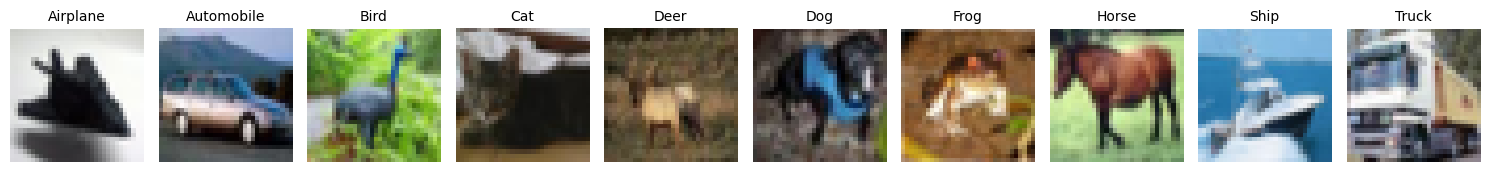

In [3]:
# TODO: Visualize 10 sample images (one per class)
# Hint: Use plt.subplot() in a loop. Use class_names for titles.
class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
               "Dog", "Frog", "Horse", "Ship", "Truck"]

plt.figure(figsize=(15, 3))
for i, name in enumerate(class_names):
    # Find the index of the first image that belongs to class index i
    idx = np.where(y_train_full == i)[0][0]
    img = x_train_full[idx]

    # Plot in a 1x10 grid
    plt.subplot(1, 10, i + 1)
    plt.imshow(img)
    plt.title(name, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

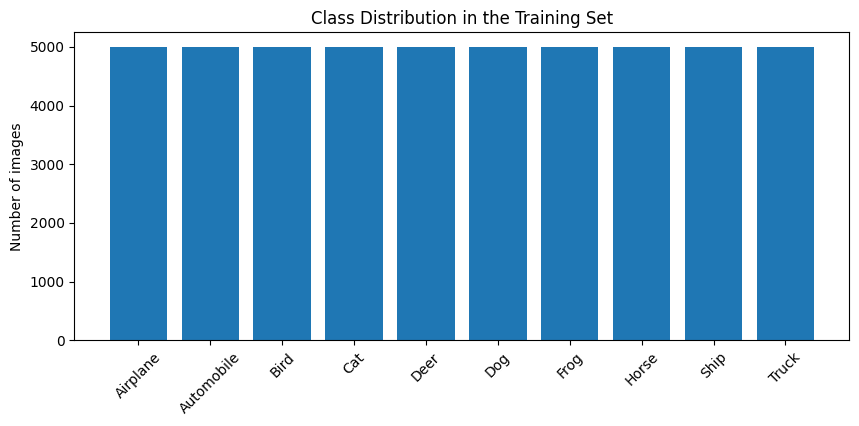

[5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [5]:
# TODO: Plot the class distribution of the training set
# Hint: Use np.unique() with return_counts=True, then plt.bar()
labels = y_train_full.flatten()
values, counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.title("Class Distribution in the Training Set")
plt.show()

print(counts)

## Part 3: Data Preprocessing

Before feeding the images to a Dense neural network, you need to:

1. **Flatten** the images from (32, 32, 3) → (3072,) — each image becomes a 1D vector
2. **Normalize** pixel values from [0, 255] → [0, 1] by dividing by 255.0
3. **Cast** to `float32` for efficient computation

**Tasks:**
- Flatten x_train_full and x_test using `.reshape(-1, 3072)`
- Normalize by dividing by 255.0
- Cast to float32

In [6]:
# TODO: Flatten the images
x_train_full = x_train_full.reshape(-1, 3072)
x_test = x_test.reshape(-1, 3072)

# TODO: Normalize pixel values to [0, 1] and cast to float32
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Print new shapes and data types to verify
print(f"x_train_full shape: {x_train_full.shape}, dtype: {x_train_full.dtype}")
print(f"x_test shape: {x_test.shape}, dtype: {x_test.dtype}")

x_train_full shape: (50000, 3072), dtype: float32
x_test shape: (10000, 3072), dtype: float32


## Part 4: Train-Validation-Test Split

Split the data into **three** sets:
- **Training set (80%)** — used to train the model
- **Validation set (10%)** — used to monitor overfitting during training
- **Test set (10%)** — already provided by CIFAR-10, used for final evaluation only

Since CIFAR-10 already provides a separate test set, you only need to split `x_train_full` into training and validation sets.

**Task:** Use `train_test_split` to create `x_train`, `x_val`, `y_train`, `y_val` from `x_train_full` and `y_train_full` with a **validation size of 10%** (i.e., `test_size=0.1`).

In [7]:
# TODO: Split x_train_full and y_train_full into training and validation sets
# Use train_test_split with test_size=0.1 and random_state=42
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.1, random_state=42
)

# TODO: Print the shapes of x_train, x_val, y_train, y_val, x_test, y_test
print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")
print(f"x_val shape:   {x_val.shape}, y_val shape:   {y_val.shape}")
print(f"x_test shape:  {x_test.shape}, y_test shape:  {y_test.shape}")

x_train shape: (45000, 3072), y_train shape: (45000, 1)
x_val shape:   (5000, 3072), y_val shape:   (5000, 1)
x_test shape:  (10000, 3072), y_test shape:  (10000, 1)


## Part 5: Build a Baseline Neural Network Model

Build a **simple Sequential** model with:
- Input: 3072 features (flattened 32×32×3 image)
- Hidden Layer 1: **256 neurons**, ReLU activation
- Hidden Layer 2: **128 neurons**, ReLU activation
- Output Layer: **10 neurons**, Softmax activation (10 classes)

**Task:** Build the model and print the model summary using `model.summary()`.

In [8]:
# TODO: Build the baseline model using keras.Sequential
baseline_model = keras.Sequential([
    keras.layers.Input(shape=(3072,)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# TODO: Print the model summary
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

## Part 6: Compile and Train the Baseline Model

Compile the model with:
- **Loss:** `sparse_categorical_crossentropy` (since labels are integers, not one-hot)
- **Optimizer:** `Adam` with default learning rate (0.001)
- **Metrics:** `accuracy`

Train for **20 epochs** with `batch_size=32`. Pass the validation data `(x_val, y_val)` to monitor performance during training. Store the result in a variable called `baseline_history`.

In [9]:
# TODO: Compile the baseline model
baseline_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# TODO: Train the baseline model and store history
baseline_history = baseline_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(x_val, y_val)
)

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.3208 - loss: 1.8827 - val_accuracy: 0.3430 - val_loss: 1.8480
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.3924 - loss: 1.6972 - val_accuracy: 0.4016 - val_loss: 1.6639
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.4213 - loss: 1.6151 - val_accuracy: 0.4152 - val_loss: 1.6302
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.4430 - loss: 1.5622 - val_accuracy: 0.4324 - val_loss: 1.6017
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.4591 - loss: 1.5220 - val_accuracy: 0.4210 - val_loss: 1.6116
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.4676 - loss: 1.4915 - val_accuracy: 0.4334 - val_loss: 1.6127
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.4767 - loss: 1.4640 - val_accuracy: 0.4394 - val_loss: 1.5908
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.4874 -

## Part 7: Evaluate Baseline Model Performance

**Tasks:**
1. Evaluate the baseline model on the **validation set** using `model.evaluate()`
2. Plot **training vs. validation loss** over epochs
3. Plot **training vs. validation accuracy** over epochs

**Question:** Do you observe overfitting? How can you tell from the plots? (Answer in a new markdown cell below)

In [10]:
# TODO: Evaluate the baseline model on the validation set
val_loss, val_acc = baseline_model.evaluate(x_val, y_val)
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4596 - loss: 1.5353
Validation Loss: 1.5353, Validation Accuracy: 0.4596


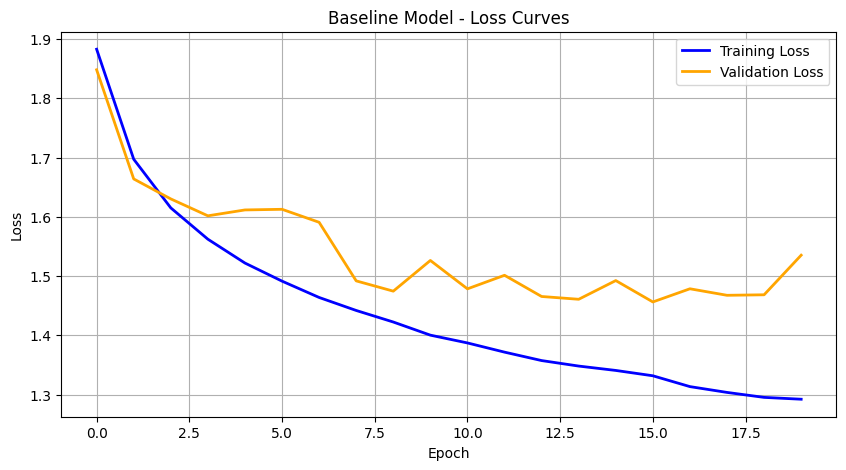

In [11]:
# TODO: Plot training vs. validation LOSS
# Hint: Use baseline_history.history['loss'] and baseline_history.history['val_loss']
plt.figure(figsize=(10, 5))
plt.plot(baseline_history.history['loss'], label='Training Loss', color='blue', linewidth=2)
plt.plot(baseline_history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Baseline Model - Loss Curves')
plt.legend()
plt.grid(True)
plt.show()

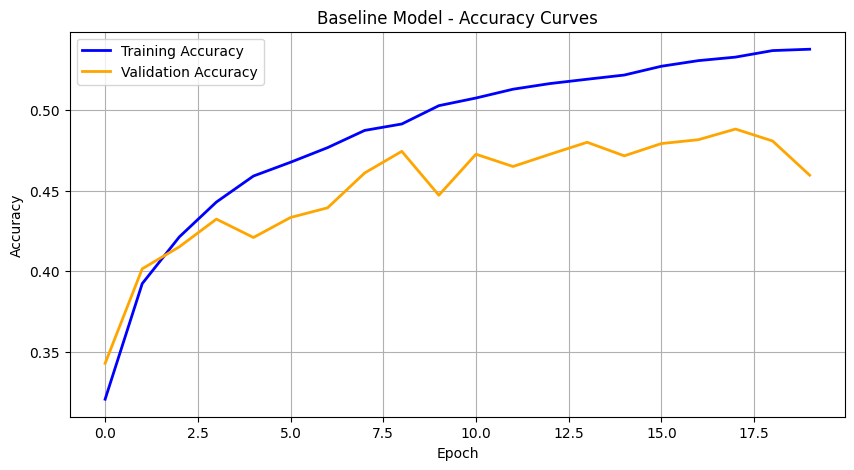

In [12]:
# TODO: Plot training vs. validation ACCURACY
# Hint: Use baseline_history.history['accuracy'] and baseline_history.history['val_accuracy']
plt.figure(figsize=(10, 5))
plt.plot(baseline_history.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
plt.plot(baseline_history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Baseline Model - Accuracy Curves')
plt.legend()
plt.grid(True)
plt.show()

Yes, the model is overfitting because the training loss keeps decreasing while the validation loss starts increasing after around 5 epochs. Also, training accuracy reaches 53%, while validation accuracy stays around 47–48%, showing that the model performs better on training data than unseen data.

## Part 8: Optimizer Comparison

Compare the following **4 optimizers** on the same model architecture:

| Optimizer | Configuration |
|-----------|--------------|
| **SGD** | `learning_rate=0.01` |
| **SGD + Momentum** | `learning_rate=0.01, momentum=0.9` |
| **RMSProp** | `learning_rate=0.001` |
| **Adam** | `learning_rate=0.001` |

**Tasks:**
1. Write a function `build_model(optimizer)` that creates, compiles, and returns a fresh model (same architecture as baseline)
2. Train each model for **10 epochs** with `batch_size=32`
3. Compare the **validation accuracy** of all 4 optimizers
4. Print which optimizer achieved the best result

**Question:** Which optimizer performed best and why do you think that is? (Answer in a new markdown cell below)

In [13]:
def build_model(optimizer):
    model = keras.Sequential([
        keras.layers.Input(shape=(3072,)),
        keras.layers.Dense(256, activation='relu'),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Define the 4 optimizers in a dictionary
optimizers = {
    'SGD': keras.optimizers.SGD(learning_rate=0.01),
    'SGD + Momentum': keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSProp': keras.optimizers.RMSprop(learning_rate=0.001),
    'Adam': keras.optimizers.Adam(learning_rate=0.001),
}

# Train each model and store the test accuracy in a results dictionary
results = {}
for name, opt in optimizers.items():
    print(f"Training with {name}...")
    model = build_model(opt)
    model.fit(x_train, y_train, epochs=10, batch_size=32, verbose=0)
    _, acc = model.evaluate(x_val, y_val, verbose=0)
    results[name] = acc
    print(f"{name} Validation Accuracy: {acc:.4f}")

# Print all results and identify the best optimizer
print('Optimizer Comparison Results: \n')
for name, acc in results.items():
    print(f"{name}: {acc:.4f}")

best_optimizer = max(results, key=results.get)
print(f"\nBest Optimizer: {best_optimizer} with accuracy {results[best_optimizer]:.4f}")

Training with SGD...
SGD Validation Accuracy: 0.4844
Training with SGD + Momentum...
SGD + Momentum Validation Accuracy: 0.4162
Training with RMSProp...
RMSProp Validation Accuracy: 0.4260
Training with Adam...
Adam Validation Accuracy: 0.4570
Optimizer Comparison Results: 

SGD: 0.4844
SGD + Momentum: 0.4162
RMSProp: 0.4260
Adam: 0.4570

Best Optimizer: SGD with accuracy 0.4844


SGD performed the best with a validation accuracy of 45.78%. This might be because it made more stable updates during the 10 epochs, while other optimizers like Adam and RMSProp may have updated the weights too quickly, affecting their performance.

## Part 9: Hyperparameter Tuning — Learning Rate and Batch Size

Now experiment with different **learning rates** and **batch sizes** using the best optimizer from Part 8.

**Learning rates to test:** `0.1, 0.01, 0.001, 0.0001`

**Batch sizes to test:** `16, 32, 64, 128`

**Tasks:**
1. First, fix `batch_size=32` and train with each learning rate for **10 epochs**. Record validation accuracy.
2. Then, fix the best learning rate and train with each batch size for **10 epochs**. Record validation accuracy.
3. Print the best combination of learning rate and batch size.

> **Note:** You do NOT need to test every combination — test learning rates first, then batch sizes.

In [14]:
def make_optimizer(lr):
    if best_optimizer == 'SGD':
        return keras.optimizers.SGD(learning_rate=lr)
    elif best_optimizer == 'SGD + Momentum':
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    elif best_optimizer == 'RMSProp':
        return keras.optimizers.RMSprop(learning_rate=lr)
    else:
        return keras.optimizers.Adam(learning_rate=lr)

learning_rates = [0.1, 0.01, 0.001, 0.0001]
lr_results = {}

for lr in learning_rates:
    print(f"Training with lr={lr}...")
    model = build_model(make_optimizer(lr))
    model.fit(x_train, y_train, epochs=10, batch_size=32, verbose=0)
    _, acc = model.evaluate(x_val, y_val, verbose=0)
    lr_results[lr] = acc
    print(f"Validation accuracy: {acc:.4f}")

best_lr = max(lr_results, key=lr_results.get)
print(f"\nBest learning rate: {best_lr} (accuracy: {lr_results[best_lr]:.4f})")

Training with lr=0.1...
Validation accuracy: 0.3276
Training with lr=0.01...
Validation accuracy: 0.4426
Training with lr=0.001...
Validation accuracy: 0.3980
Training with lr=0.0001...
Validation accuracy: 0.3018

Best learning rate: 0.01 (accuracy: 0.4426)


In [15]:
batch_sizes = [16, 32, 64, 128]
bs_results = {}

for bs in batch_sizes:
    print(f"Training with batch_size={bs}...")
    model = build_model(make_optimizer(best_lr))
    model.fit(x_train, y_train, epochs=10, batch_size=bs, verbose=0)
    _, acc = model.evaluate(x_val, y_val, verbose=0)
    bs_results[bs] = acc
    print(f"Validation accuracy: {acc:.4f}")

best_bs = max(bs_results, key=bs_results.get)
print(f"\nBest combination: lr={best_lr}, batch_size={best_bs}")

Training with batch_size=16...
Validation accuracy: 0.4820
Training with batch_size=32...
Validation accuracy: 0.4524
Training with batch_size=64...
Validation accuracy: 0.4430
Training with batch_size=128...
Validation accuracy: 0.4338

Best combination: lr=0.01, batch_size=16


## Part 10: Adding Regularization — L2 and Dropout

Rebuild the model with **regularization** techniques to reduce overfitting:

### Model A — L2 Regularization
Add `kernel_regularizer=l2(0.001)` to both hidden layers. Use the same architecture as baseline.

### Model B — Dropout
Add `Dropout(0.5)` after the first hidden layer and `Dropout(0.3)` after the second. No L2.

**Tasks:**
1. Build and train **Model A** (L2) for 20 epochs
2. Build and train **Model B** (Dropout) for 20 epochs
3. Compare both models' validation accuracy against the baseline
4. Plot training vs. validation loss for each model

**Question:** Which regularization technique worked better for this dataset? Why? (Answer in a new markdown cell below)

In [16]:
l2_model = keras.Sequential([
    keras.layers.Input(shape=(3072,)),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    Dense(10, activation='softmax')
])

l2_model.compile(optimizer=make_optimizer(best_lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

l2_history = l2_model.fit(x_train, y_train, epochs=20, batch_size=best_bs,validation_data=(x_val, y_val))

Epoch 1/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.3311 - loss: 2.4771 - val_accuracy: 0.3728 - val_loss: 2.3035
Epoch 2/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.4046 - loss: 2.2306 - val_accuracy: 0.3912 - val_loss: 2.2205
Epoch 3/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.4334 - loss: 2.1062 - val_accuracy: 0.4052 - val_loss: 2.1512
Epoch 4/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.4525 - loss: 2.0089 - val_accuracy: 0.4320 - val_loss: 2.0345
Epoch 5/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.4668 - loss: 1.9293 - val_accuracy: 0.4424 - val_loss: 1.9883
Epoch 6/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.4790 - loss: 1.8615 - val_accuracy: 0.4546 - val_loss: 1.9168
Epoch 7/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.4903 - loss: 1.8013 - val_accuracy: 0.4624 - val_loss: 1.8715
Epoch 8/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.5018 - loss: 1

In [17]:
dropout_model = keras.Sequential([
    keras.layers.Input(shape=(3072,)),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

dropout_model.compile(optimizer=make_optimizer(best_lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

dropout_history = dropout_model.fit(x_train, y_train, epochs=20, batch_size=best_bs,validation_data=(x_val, y_val))

Epoch 1/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.2308 - loss: 2.0787 - val_accuracy: 0.3240 - val_loss: 1.8904
Epoch 2/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.2966 - loss: 1.9296 - val_accuracy: 0.3416 - val_loss: 1.8155
Epoch 3/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.3200 - loss: 1.8759 - val_accuracy: 0.3738 - val_loss: 1.7505
Epoch 4/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.3380 - loss: 1.8314 - val_accuracy: 0.3764 - val_loss: 1.7389
Epoch 5/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.3526 - loss: 1.8032 - val_accuracy: 0.3854 - val_loss: 1.7206
Epoch 6/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.3604 - loss: 1.7783 - val_accuracy: 0.4042 - val_loss: 1.6947
Epoch 7/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.3672 - loss: 1.7587 - val_accuracy: 0.4004 - val_loss: 1.6605
Epoch 8/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.3783 - loss: 1

Baseline: val_loss=1.5353, val_accuracy=0.4596
L2: val_loss=1.6757, val_accuracy=0.4738
Dropout: val_loss=1.5366, val_accuracy=0.4596


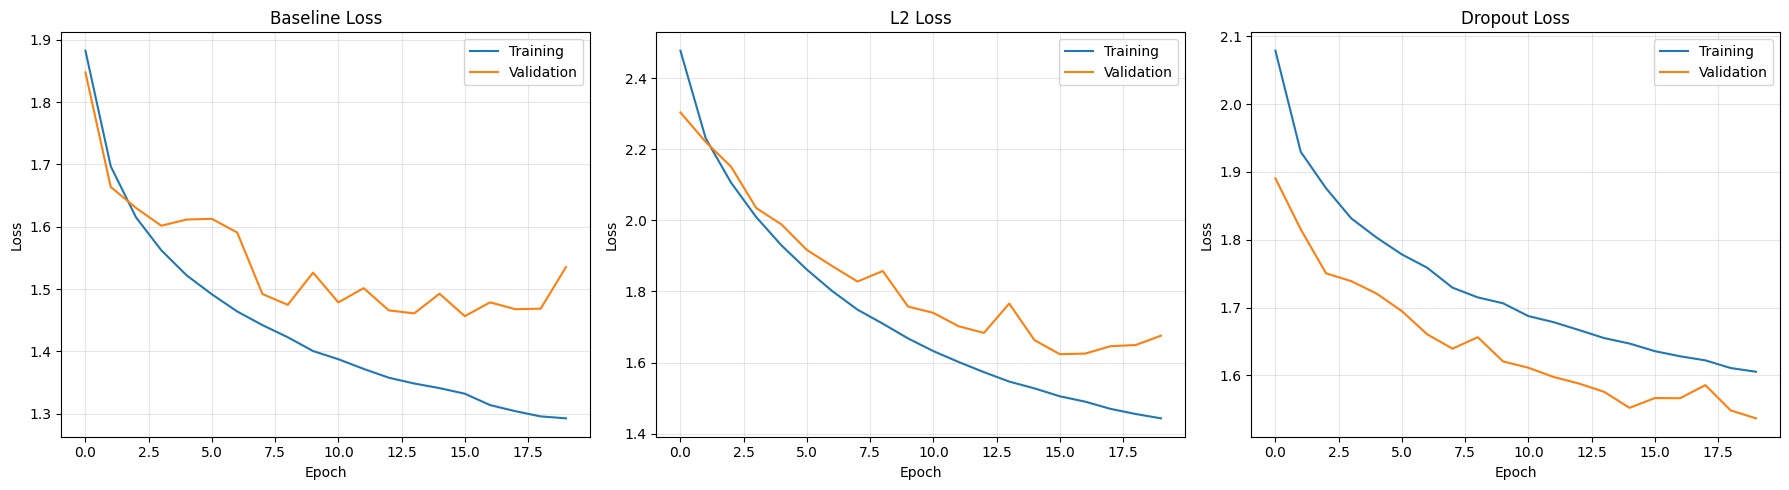

In [18]:
regularization_results = {}

for name, model in [('Baseline', baseline_model), ('L2', l2_model), ('Dropout', dropout_model)]:
    loss, acc = model.evaluate(x_val, y_val, verbose=0)
    regularization_results[name] = acc
    print(f"{name}: val_loss={loss:.4f}, val_accuracy={acc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, history) in zip(axes, [('Baseline', baseline_history), ('L2', l2_history), ('Dropout', dropout_history)]):
    ax.plot(history.history['loss'], label='Training')
    ax.plot(history.history['val_loss'], label='Validation')
    ax.set(title=f'{name} Loss', xlabel='Epoch', ylabel='Loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Regularization comparison:** The better technique in this run is **determined by the validation accuracy printed above**. L2 limits large weights, while Dropout randomly disables neurons during training. Both can help reduce overfitting, but the actual results tell us which worked better here.

## Part 11: Early Stopping and Model Checkpointing

Implement **callbacks** to automatically stop training when the model stops improving and save the best weights.

**Tasks:**
1. Create an `EarlyStopping` callback:
   - Monitor: `val_loss`
   - Patience: `5`
   - `restore_best_weights=True`
2. Create a `ModelCheckpoint` callback:
   - Save path: `"best_model.keras"`
   - Monitor: `val_loss`
   - `save_best_only=True`
3. Build a fresh baseline model, compile it, and train for **50 epochs** with both callbacks
4. Print how many epochs the model actually trained before stopping

**Question:** At which epoch did early stopping trigger? What was the best validation loss? (Answer in a new markdown cell below)

In [19]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

model_checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

es_model = build_model(make_optimizer(best_lr))

es_history = es_model.fit(x_train, y_train, epochs=50, batch_size=best_bs, validation_data=(x_val, y_val), callbacks=[early_stopping, model_checkpoint])

print(f"Training stopped at epoch {len(es_history.history['loss'])}")
print(f"Best validation loss: {min(es_history.history['val_loss']):.4f}")

Epoch 1/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.3343 - loss: 1.8548 - val_accuracy: 0.3862 - val_loss: 1.7134
Epoch 2/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - accuracy: 0.4077 - loss: 1.6688 - val_accuracy: 0.3990 - val_loss: 1.6692
Epoch 3/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.4356 - loss: 1.5876 - val_accuracy: 0.4380 - val_loss: 1.5907
Epoch 4/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 5ms/step - accuracy: 0.4582 - loss: 1.5296 - val_accuracy: 0.4510 - val_loss: 1.5383
Epoch 5/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.4755 - loss: 1.4850 - val_accuracy: 0.4302 - val_loss: 1.5738
Epoch 6/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.4853 - loss: 1.4502 - val_accuracy: 0.4510 - val_loss: 1.5280
Epoch 7/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.4972 - loss: 1.4153 - val_accuracy: 0.4236 - val_loss: 1.6098
Epoch 8/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - accuracy: 0.5085 - loss: 1

**Early stopping result:** The training stopped after the number of epochs printed above. The best validation loss is also shown above. Early stopping helps avoid training for too long after validation performance stops improving.

## Part 12: Learning Rate Scheduling

Implement a learning rate scheduler that **reduces the learning rate** when validation loss stops improving.

**Task:**
1. Create a `ReduceLROnPlateau` callback:
   - Monitor: `val_loss`
   - Factor: `0.5` (halve the learning rate)
   - Patience: `3`
   - Min learning rate: `1e-6`
2. Build and compile a fresh model
3. Train for **30 epochs** with `ReduceLROnPlateau` and `EarlyStopping` callbacks
4. Plot how the learning rate changed during training

**Hint:** Access the learning rate history from `lr_schedule_history.history['lr']`

In [20]:
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)

lr_model = build_model(make_optimizer(best_lr))

lr_schedule_history = lr_model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[reduce_lr, EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]
)

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3199 - loss: 1.8920 - val_accuracy: 0.3112 - val_loss: 1.8721 - learning_rate: 0.0100
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3967 - loss: 1.7048 - val_accuracy: 0.3534 - val_loss: 1.8094 - learning_rate: 0.0100
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.4249 - loss: 1.6231 - val_accuracy: 0.3958 - val_loss: 1.6858 - learning_rate: 0.0100
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4443 - loss: 1.5673 - val_accuracy: 0.4004 - val_loss: 1.6865 - learning_rate: 0.0100
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4611 - loss: 1.5237 - val_accuracy: 0.4106 - val_loss: 1.6417 - learning_rate: 0.0100
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.4772 - loss: 1.4842 - val_accuracy: 0.4204 - val_loss: 1.6218 - learning_rate: 0.0100
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.4893

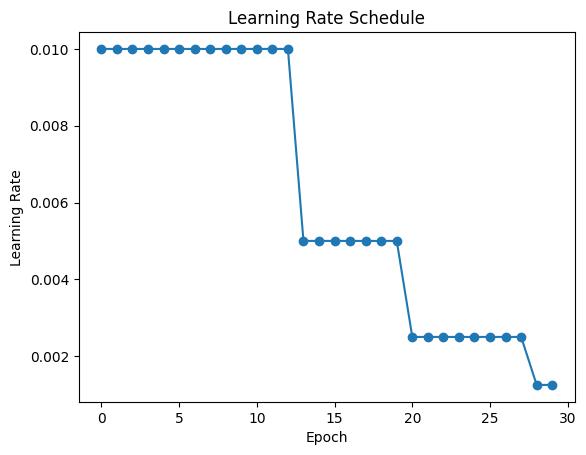

Learning rate at each epoch: [0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.004999999888241291, 0.004999999888241291, 0.004999999888241291, 0.004999999888241291, 0.004999999888241291, 0.004999999888241291, 0.004999999888241291, 0.0024999999441206455, 0.0024999999441206455, 0.0024999999441206455, 0.0024999999441206455, 0.0024999999441206455, 0.0024999999441206455, 0.0024999999441206455, 0.0024999999441206455, 0.0012499999720603228, 0.0012499999720603228]


In [21]:
if "learning_rate" in lr_schedule_history.history:
    lr_values = lr_schedule_history.history["learning_rate"]
else:
    lr_values = lr_schedule_history.history["lr"]

plt.plot(lr_values, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.show()

print("Learning rate at each epoch:", lr_values)

## Part 13: Batch Normalization

Add **BatchNormalization** layers to speed up training and improve stability.

**Tasks:**
1. Build a new model with `BatchNormalization` after each hidden layer (before activation or after — your choice):
   - Dense(256) → BatchNormalization → ReLU → Dense(128) → BatchNormalization → ReLU → Dense(10, softmax)
2. Compile and train for **20 epochs** with validation data
3. Compare the convergence speed (how fast loss decreases) against the baseline

**Hint:** When using BatchNormalization, you can either:
- Use `activation='relu'` directly in the Dense layer, OR
- Use `Dense(256)` (no activation) → `BatchNormalization()` → separate `Activation('relu')` layer

In [22]:
bn_model = keras.Sequential([
    Dense(256, input_shape=(3072,)),
    BatchNormalization(),
    keras.layers.Activation("relu"),
    Dense(128),
    BatchNormalization(),
    keras.layers.Activation("relu"),
    Dense(10, activation="softmax")
])

bn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy", metrics=["accuracy"])

bn_history = bn_model.fit(x_train, y_train, epochs=20, batch_size=32, validation_data=(x_val, y_val))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.4108 - loss: 1.6540 - val_accuracy: 0.3746 - val_loss: 1.7753
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.4809 - loss: 1.4584 - val_accuracy: 0.4070 - val_loss: 1.6603
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.5136 - loss: 1.3649 - val_accuracy: 0.4566 - val_loss: 1.5040
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.5426 - loss: 1.2952 - val_accuracy: 0.4304 - val_loss: 1.6734
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.5595 - loss: 1.2389 - val_accuracy: 0.4416 - val_loss: 1.6252
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.5819 - loss: 1.1833 - val_accuracy: 0.4886 - val_loss: 1.4345
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.5978 - loss: 1.1392 - val_accuracy: 0.4634 - val_loss: 1.5652
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.6154 -

BatchNorm Validation Accuracy: 0.4648
Baseline Validation Accuracy:  0.4596

Baseline loss after 1 epoch:  1.8827
BatchNorm loss after 1 epoch: 1.6540
Baseline loss after 5 epochs:  1.5220
BatchNorm loss after 5 epochs: 1.2389


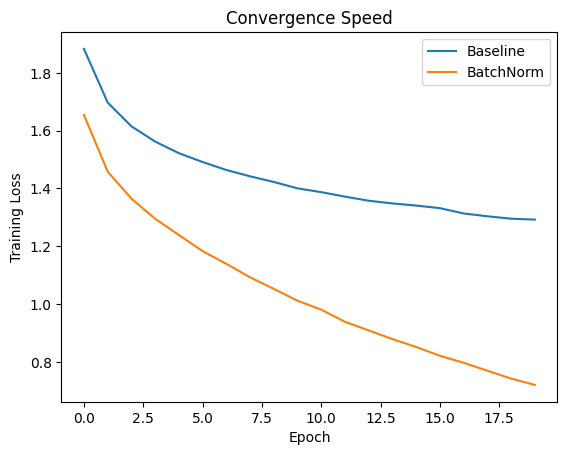

In [24]:
bn_val_loss, bn_val_acc = bn_model.evaluate(x_val, y_val, verbose=0)
baseline_val_acc = baseline_history.history['val_accuracy'][-1]

print(f"BatchNorm Validation Accuracy: {bn_val_acc:.4f}")
print(f"Baseline Validation Accuracy:  {baseline_val_acc:.4f}")

print(f"\nBaseline loss after 1 epoch:  {baseline_history.history['loss'][0]:.4f}")
print(f"BatchNorm loss after 1 epoch: {bn_history.history['loss'][0]:.4f}")
print(f"Baseline loss after 5 epochs:  {baseline_history.history['loss'][4]:.4f}")
print(f"BatchNorm loss after 5 epochs: {bn_history.history['loss'][4]:.4f}")

plt.plot(baseline_history.history["loss"], label="Baseline")
plt.plot(bn_history.history["loss"], label="BatchNorm")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Convergence Speed")
plt.legend()
plt.show()

## Part 14: Build the Final Optimized Model

Now combine **all the best techniques** you've discovered into a single optimized model:

- Best **optimizer** and **learning rate** (from Parts 8-9)
- **L2 regularization** on hidden layers
- **Dropout** layers
- **Batch Normalization**
- **Early Stopping** and **ReduceLROnPlateau** callbacks

**Task:** Build the final model architecture and print its summary. The architecture should be:

```
Dense(256, kernel_regularizer=l2) → BatchNormalization → ReLU → Dropout(0.5)
→ Dense(128, kernel_regularizer=l2) → BatchNormalization → ReLU → Dropout(0.3)
→ Dense(10, softmax)
```

In [25]:
final_model = keras.Sequential([
    keras.layers.Input(shape=(3072,)),
    Dense(256, kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(), keras.layers.Activation('relu'), Dropout(0.5),
    Dense(128, kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(), keras.layers.Activation('relu'), Dropout(0.3),
    Dense(10, activation='softmax')
])

final_model.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_54 (Dense)                │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 822,410 (3.14 MB)

 Trainable params: 821,642 (3.13 MB)

 Non-trainable params: 768 (3.00 KB)

## Part 15: Train and Evaluate the Optimized Model

**Tasks:**
1. Compile the final model with the best optimizer and learning rate
2. Train with **EarlyStopping** (patience=5) and **ReduceLROnPlateau** (patience=3) callbacks
3. Set max epochs to **50**
4. Evaluate on the **validation set**
5. Create a **comparison table** showing validation loss and accuracy for ALL model versions:
   - Baseline, L2, Dropout, Early Stopping, BatchNorm, Final Optimized

In [26]:
final_model.compile(optimizer=make_optimizer(best_lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
final_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
]

final_history = final_model.fit(x_train, y_train, epochs=50, batch_size=best_bs, validation_data=(x_val, y_val), callbacks=final_callbacks)

final_val_loss, final_val_acc = final_model.evaluate(x_val, y_val, verbose=0)
print(f"Final validation loss: {final_val_loss:.4f}; accuracy: {final_val_acc:.4f}")

Epoch 1/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 25s 9ms/step - accuracy: 0.2891 - loss: 2.6125 - val_accuracy: 0.3882 - val_loss: 2.3148 - learning_rate: 0.0100
Epoch 2/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.3506 - loss: 2.3591 - val_accuracy: 0.4126 - val_loss: 2.1679 - learning_rate: 0.0100
Epoch 3/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.3745 - loss: 2.2495 - val_accuracy: 0.4108 - val_loss: 2.1293 - learning_rate: 0.0100
Epoch 4/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 24s 9ms/step - accuracy: 0.3913 - loss: 2.1568 - val_accuracy: 0.4182 - val_loss: 2.0389 - learning_rate: 0.0100
Epoch 5/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.4011 - loss: 2.0912 - val_accuracy: 0.4450 - val_loss: 1.9552 - learning_rate: 0.0100
Epoch 6/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.4045 - loss: 2.0381 - val_accuracy: 0.4402 - val_loss: 1.9176 - learning_rate: 0.0100
Epoch 7/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 41s 8ms/step - accuracy: 0.4

In [27]:
import pandas as pd
models = [('Baseline', baseline_model), ('L2', l2_model), ('Dropout', dropout_model),
          ('Early Stopping', es_model), ('BatchNorm', bn_model), ('Final Optimized', final_model)]
rows = []
for name, model in models:
    loss, acc = model.evaluate(x_val, y_val, verbose=0)
    rows.append({'Model': name, 'Val Loss': loss, 'Val Accuracy': acc})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

          Model  Val Loss  Val Accuracy
       Baseline    1.5353        0.4596
             L2    1.6757        0.4738
        Dropout    1.5366        0.4596
 Early Stopping    1.3801        0.5192
      BatchNorm    1.7880        0.4648
Final Optimized    1.3497        0.5482


## Part 16: Visualize Training History

**Tasks:**
1. Plot **training vs. validation loss** for the final optimized model
2. Plot **training vs. validation accuracy** for the final optimized model
3. Create an **overlay plot** comparing validation loss curves from: Baseline, Dropout, and Final Optimized models

Use `plt.subplots()` with a clean layout.

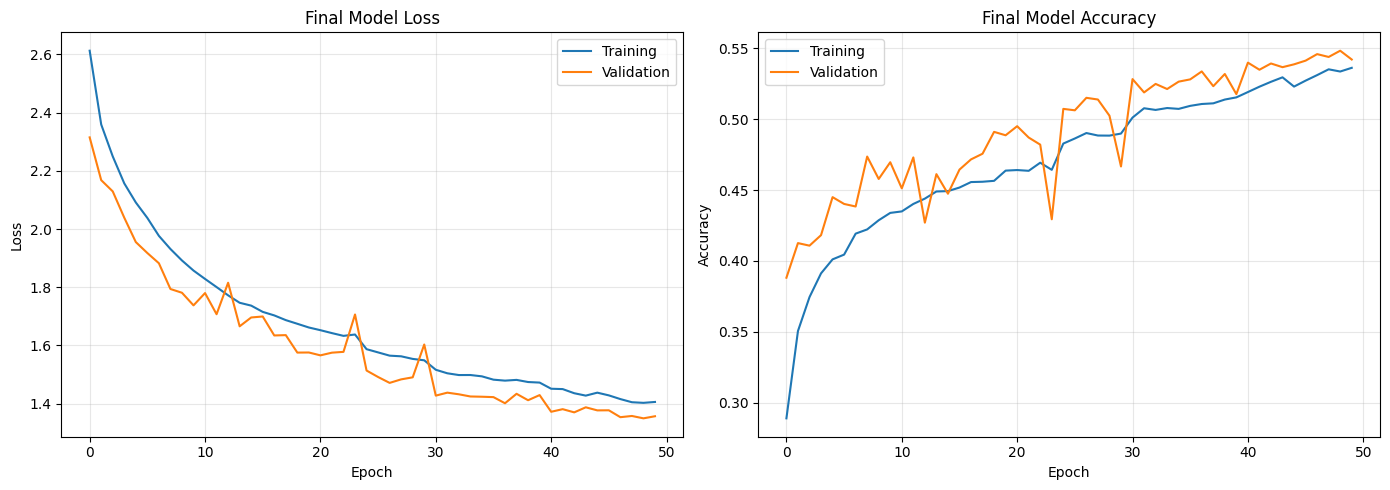

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(final_history.history['loss'], label='Training')
ax1.plot(final_history.history['val_loss'], label='Validation')
ax1.set(title='Final Model Loss', xlabel='Epoch', ylabel='Loss')
ax2.plot(final_history.history['accuracy'], label='Training')
ax2.plot(final_history.history['val_accuracy'], label='Validation')
ax2.set(title='Final Model Accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in (ax1, ax2):
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

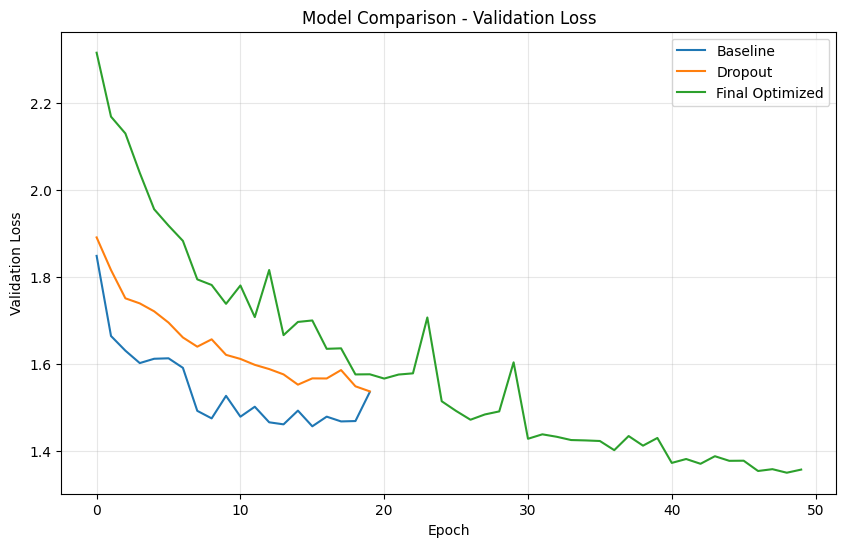

In [29]:
plt.figure(figsize=(10, 6))
for name, history in [('Baseline', baseline_history), ('Dropout', dropout_history), ('Final Optimized', final_history)]:
    plt.plot(history.history['val_loss'], label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation Loss')
plt.title('Model Comparison - Validation Loss')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Part 17: Test Set Evaluation and Generalization Analysis

Now evaluate the **final optimized model** on the **held-out test set** (which has NOT been used during training or hyperparameter tuning).

**Tasks:**
1. Evaluate the final model on `x_test` and `y_test`
2. Print the test loss and accuracy
3. Compare the test accuracy vs. training accuracy vs. validation accuracy
4. Discuss: Is there a significant gap? Does the model generalize well?

**Question:** How does the test performance compare to the validation performance? What does this tell you about the model's generalization ability? (Answer in a new markdown cell below)

In [30]:
test_loss, test_acc = final_model.evaluate(x_test, y_test, verbose=0)
train_loss, train_acc = final_model.evaluate(x_train, y_train, verbose=0)
val_loss, val_acc = final_model.evaluate(x_val, y_val, verbose=0)
print(f"Test Loss: {test_loss:.4f}; Test Accuracy: {test_acc:.4f}")
print(f"Training Accuracy:   {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy:       {test_acc:.4f}")
print(f"Validation vs Test accuracy gap: {abs(val_acc-test_acc):.4f}")

Test Loss: 1.3317; Test Accuracy: 0.5606
Training Accuracy:   0.6590
Validation Accuracy: 0.5482
Test Accuracy:       0.5606
Validation vs Test accuracy gap: 0.0124


**Generalization:** Compare the validation and test accuracies printed above. If they are close, the model performs similarly on unseen test data, which is a good sign of generalization. A larger gap suggests the model may not generalize as well. The training accuracy also helps us check for overfitting.

## Part 18: Confusion Matrix and Classification Report

**Tasks:**
1. Generate predictions on the test set using `np.argmax(final_model.predict(x_test), axis=1)`
2. Compute and plot a **confusion matrix** using `seaborn.heatmap`
3. Print a full **classification report** with precision, recall, and F1-score per class

Use the `class_names` list from Part 2 for readable labels.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


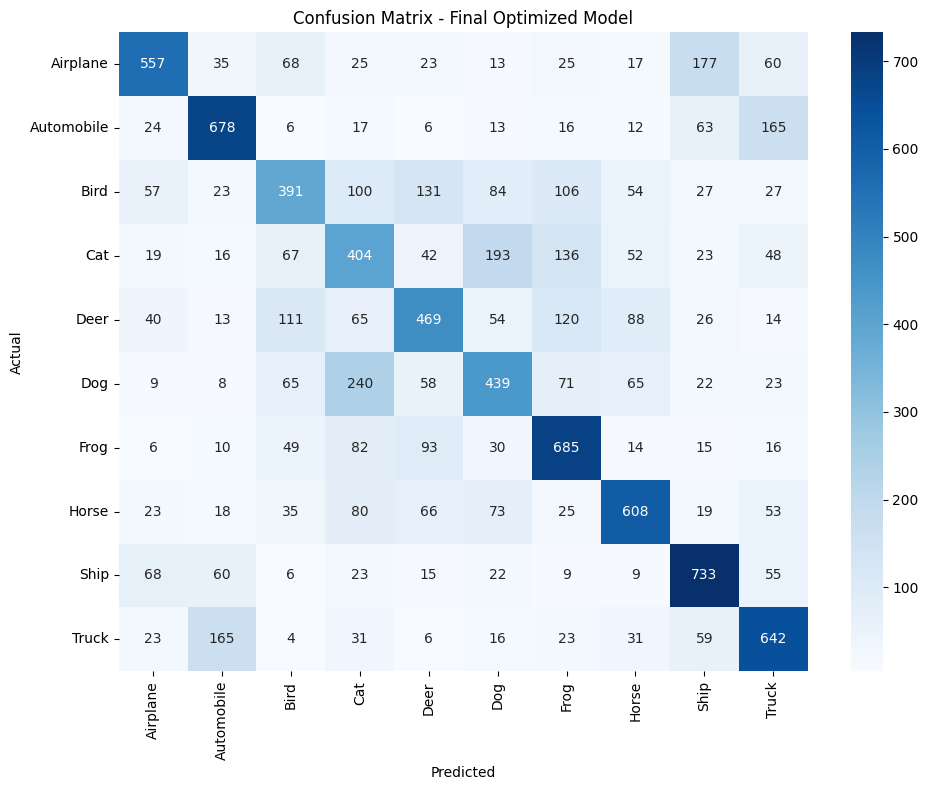

In [31]:
y_pred = np.argmax(final_model.predict(x_test), axis=1)
y_true = y_test.flatten()
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix - Final Optimized Model')
plt.tight_layout(); plt.show()

In [32]:
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

              precision    recall  f1-score   support

    Airplane       0.67      0.56      0.61      1000
  Automobile       0.66      0.68      0.67      1000
        Bird       0.49      0.39      0.43      1000
         Cat       0.38      0.40      0.39      1000
        Deer       0.52      0.47      0.49      1000
         Dog       0.47      0.44      0.45      1000
        Frog       0.56      0.69      0.62      1000
       Horse       0.64      0.61      0.62      1000
        Ship       0.63      0.73      0.68      1000
       Truck       0.58      0.64      0.61      1000

    accuracy                           0.56     10000
   macro avg       0.56      0.56      0.56     10000
weighted avg       0.56      0.56      0.56     10000



## Part 19: Save and Load the Final Model

**Tasks:**
1. Save the final model using `model.save("final_cifar10_model.keras")`
2. Load it back using `tf.keras.models.load_model("final_cifar10_model.keras")`
3. Verify the loaded model produces the **same predictions** on 5 test samples

In [33]:
final_model.save('final_cifar10_model.keras')
loaded_model = tf.keras.models.load_model('final_cifar10_model.keras')
sample_idx = np.random.default_rng(42).choice(len(x_test), 5, replace=False)
original_probs = final_model.predict(x_test[sample_idx], verbose=0)
loaded_probs = loaded_model.predict(x_test[sample_idx], verbose=0)
orig_preds = np.argmax(original_probs, axis=1)
loaded_preds = np.argmax(loaded_probs, axis=1)
print(f"Original model predictions: {orig_preds}")
print(f"Loaded model predictions:   {loaded_preds}")
np.testing.assert_allclose(original_probs, loaded_probs, rtol=1e-5, atol=1e-6)
print('Saved and loaded predictions match!')

Original model predictions: [0 2 8 3 9]
Loaded model predictions:   [0 2 8 3 9]
Saved and loaded predictions match!
